# **Telecom Customer Churn and Sales Trends Analysis**

In this notebook, I analyze customer and subscription datasets to help my company understand customer churn and sales trends over the past year.

In [ ]:
import pandas as pd

In [ ]:
customer = pd.read_csv('data/Customers.csv')
subscription = pd.read_csv('data/Subscriptions.csv')
usage = pd.read_csv('data/Usage.csv')

### EDA and some data cleaning

In [ ]:
def view(dataset, name):
  print('let\'s veiw', name, 'dataset')
  print("Is there any duplicated rows?",dataset.duplicated().sum())

  for col in dataset.columns:
    print('Does the column ('+col+') have duplicated values?')
    print(dataset[col].duplicated().sum())
    print('Does the column ('+col+') has any missing values?')
    print(dataset[col].isna().sum())
    print('what are the unique values of the column ('+col+')?')
    print(dataset[col].unique() )
    print("frequancy of unique values of the column ("+col+"):")
    print(dataset[col].value_counts())
    print('----------------------------------------------------------------\n')


In [ ]:
customer.head()

/usr/local/lib/python3.11/dist-packages/google/colab/_dataframe_summarizer.py:88: UserWarning: Could not infer format, so each element will be parsed individually, falling back to `dateutil`. To ensure parsing is consistent and as-expected, please specify a format.
  cast_date_col = pd.to_datetime(column, errors="coerce")


,Customer ID,Name,Email,Status,Active Date,Churned Date
0,1001,Customer_1,customer1@example.com,Active,11-04-22,NaN
1,1002,Customer_2,customer2@example.com,Churned,01-24-22,12-06-22
2,1003,Customer_3,customer3@example.com,Churned,05-08-22,02-06-23
3,1004,Customer_4,customer4@example.com,Active,04-05-22,NaN
4,1005,Customer_5,customer5@example.com,Active,12-04-22,NaN


In [ ]:
customer.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 6 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Customer ID   20 non-null     int64 
 1   Name          20 non-null     object
 2   Email         20 non-null     object
 3   Status        20 non-null     object
 4   Active Date   20 non-null     object
 5   Churned Date  6 non-null      object
dtypes: int64(1), object(5)
memory usage: 1.1+ KB


In [ ]:
customer['Customer ID'] = customer['Customer ID'].astype(object)

customer['Active Date'] = pd.to_datetime(customer['Active Date'], format='%m-%d-%y')
customer['Churned Date'] = pd.to_datetime(customer['Churned Date'], format='%m-%d-%y')

In [ ]:
customer.describe(include=['object'])

,Customer ID,Name,Email,Status
count,20,20,20,20
unique,20,20,20,2
top,1001,Customer_1,customer1@example.com,Active
freq,1,1,1,14


In [ ]:
customer.describe(include=['datetime'])

,Active Date,Churned Date
count,20,6
mean,2022-07-09 04:48:00,2023-03-28 00:00:00
min,2022-01-01 00:00:00,2022-08-05 00:00:00
25%,2022-04-01 18:00:00,2022-12-21 12:00:00
50%,2022-07-29 00:00:00,2023-03-19 00:00:00
75%,2022-10-19 06:00:00,2023-06-01 18:00:00
max,2022-12-21 00:00:00,2024-01-10 00:00:00


In [ ]:
view(customer, "customers data")

let's veiw customers data dataset
Is there any duplicated rows? 0
Does the column (Customer ID) have duplicated values?
0
Does the column (Customer ID) has any missing values?
0
what are the unique values of the column (Customer ID)?
[1001 1002 1003 1004 1005 1006 1007 1008 1009 1010 1011 1012 1013 1014
 1015 1016 1017 1018 1019 1020]
frequancy of unique values of the column (Customer ID):
Customer ID
1001    1
1002    1
1003    1
1004    1
1005    1
1006    1
1007    1
1008    1
1009    1
1010    1
1011    1
1012    1
1013    1
1014    1
1015    1
1016    1
1017    1
1018    1
1019    1
1020    1
Name: count, dtype: int64
----------------------------------------------------------------

Does the column (Name) have duplicated values?
0
Does the column (Name) has any missing values?
0
what are the unique values of the column (Name)?
['Customer_1' 'Customer_2' 'Customer_3' 'Customer_4' 'Customer_5'
 'Customer_6' 'Customer_7' 'Customer_8' 'Customer_9' 'Customer_10'
 'Customer_11' 'Custome

In [ ]:
# notes on customers data:
# to know if a customer is churned, it is not sufficient to check his (Status), also check if they has a (churn data)

In [ ]:
subscription.head()

,Subscription ID,Customer ID,Plan Name,Start Date,End Date
0,5001.0,1001.0,Bronze Plan,11-04-23,07-11-24
1,5002.0,1002.0,Bronze Plan,01-24-23,05-05-24
2,5003.0,1003.0,Silver Plan,05-08-23,04-25-24
3,5004.0,1004.0,Platnum Plan,04-05-23,06-04-24
4,5005.0,1005.0,Platinum Plan,12-04-23,02-13-24


In [ ]:
subscription.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 21 entries, 0 to 20
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Subscription ID  20 non-null     float64
 1   Customer ID      20 non-null     float64
 2   Plan Name        20 non-null     object 
 3   Start Date       20 non-null     object 
 4   End Date         20 non-null     object 
dtypes: float64(2), object(3)
memory usage: 972.0+ bytes


In [ ]:
subscription['Customer ID'] = subscription['Customer ID'].astype(object)
subscription['Subscription ID'] = subscription['Subscription ID'].astype(object)

subscription['Start Date'] = pd.to_datetime(subscription['Start Date'], format='%m-%d-%y')
subscription['End Date'] = pd.to_datetime(subscription['End Date'], format='%m-%d-%y')

In [ ]:
subscription.describe(include=['object'])

,Subscription ID,Customer ID,Plan Name
count,20.0,20.0,20
unique,20.0,20.0,5
top,5001.0,1001.0,Bronze Plan
freq,1.0,1.0,7


In [ ]:
subscription.describe(include=['datetime'])

,Start Date,End Date
count,20,20
mean,2023-07-09 04:48:00,2024-05-13 14:24:00
min,2023-01-01 00:00:00,2024-01-24 00:00:00
25%,2023-04-01 18:00:00,2024-02-16 18:00:00
50%,2023-07-29 00:00:00,2024-05-04 00:00:00
75%,2023-10-19 06:00:00,2024-06-19 06:00:00
max,2023-12-21 00:00:00,2024-11-20 00:00:00


In [ ]:
view(subscription, "subscription data")

let's veiw subscription data dataset
Is there any duplicated rows? 0
Does the column (Subscription ID) have duplicated values?
0
Does the column (Subscription ID) has any missing values?
1
what are the unique values of the column (Subscription ID)?
[5001.0 5002.0 5003.0 5004.0 5005.0 5006.0 5007.0 5008.0 5009.0 5010.0
 5011.0 5012.0 5013.0 5014.0 5015.0 5016.0 5017.0 5018.0 5019.0 5020.0 nan]
frequancy of unique values of the column (Subscription ID):
Subscription ID
5001.0    1
5002.0    1
5003.0    1
5004.0    1
5005.0    1
5006.0    1
5007.0    1
5008.0    1
5009.0    1
5010.0    1
5011.0    1
5012.0    1
5013.0    1
5014.0    1
5015.0    1
5016.0    1
5017.0    1
5018.0    1
5019.0    1
5020.0    1
Name: count, dtype: int64
----------------------------------------------------------------

Does the column (Customer ID) have duplicated values?
0
Does the column (Customer ID) has any missing values?
1
what are the unique values of the column (Customer ID)?
[1001.0 1002.0 1003.0 1004.0

In [ ]:
# notes on subsciption data:
# missing values in (Subscription ID), (Customer ID), (Start Date) and (End Date). inconsistancy in (Plan Name)
# after investtigation, there is 1 row with only nulls, so we will drop it
# we can add a new column (subscription type) based on the (Start Date) and (End Date)

print(subscription[subscription['Subscription ID'].isna()])

subscription.dropna(inplace=True)
subscription['Plan Name'] = subscription['Plan Name'].replace({'Platnum Plan': 'Platinum Plan'})

   Subscription ID Customer ID Plan Name Start Date End Date
20             NaN         NaN       NaN        NaT      NaT


In [ ]:
usage.head()

,Customer ID,Month,Data Usage GB,Minutes Used
0,1001,2023-01,6.47,203
1,1001,2023-02,2.53,489
2,1001,2023-03,1.59,384
3,1001,2023-04,9.54,564
4,1001,2023-05,9.69,750


In [ ]:
usage.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 4 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Customer ID    240 non-null    int64  
 1   Month          240 non-null    object 
 2   Data Usage GB  240 non-null    float64
 3   Minutes Used   240 non-null    int64  
dtypes: float64(1), int64(2), object(1)
memory usage: 7.6+ KB


In [ ]:
usage['Customer ID'] = usage['Customer ID'].astype(object)
usage['Month'] = pd.to_datetime(usage['Month'], format='%Y-%m')

In [ ]:
usage.describe()

,Month,Data Usage GB,Minutes Used
count,240,240.000000,240.000000
mean,2023-06-16 12:00:00,5.509625,550.333333
min,2023-01-01 00:00:00,1.050000,100.000000
25%,2023-03-24 06:00:00,3.180000,328.750000
50%,2023-06-16 00:00:00,5.635000,564.000000
75%,2023-09-08 12:00:00,7.850000,769.500000
max,2023-12-01 00:00:00,9.910000,999.000000
std,NaN,2.672222,257.063684


In [ ]:
usage.describe(include=['object'])

,Customer ID
count,240
unique,20
top,1001
freq,12


In [ ]:
view(usage, "usage data")

let's veiw usage data dataset
Is there any duplicated rows? 0
Does the column (Customer ID) have duplicated values?
220
Does the column (Customer ID) has any missing values?
0
what are the unique values of the column (Customer ID)?
[1001 1002 1003 1004 1005 1006 1007 1008 1009 1010 1011 1012 1013 1014
 1015 1016 1017 1018 1019 1020]
frequancy of unique values of the column (Customer ID):
Customer ID
1001    12
1002    12
1003    12
1004    12
1005    12
1006    12
1007    12
1008    12
1009    12
1010    12
1011    12
1012    12
1013    12
1014    12
1015    12
1016    12
1017    12
1018    12
1019    12
1020    12
Name: count, dtype: int64
----------------------------------------------------------------

Does the column (Month) have duplicated values?
228
Does the column (Month) has any missing values?
0
what are the unique values of the column (Month)?
<DatetimeArray>
['2023-01-01 00:00:00', '2023-02-01 00:00:00', '2023-03-01 00:00:00',
 '2023-04-01 00:00:00', '2023-05-01 00:00:00', 

In [ ]:
# notes on usage data:
# the data shows each customer usage of (Data Usage GB) and (Minutes Used) over the last 12 monthes

### **Task 1**   
Calculate the number of active vs churned customers.


In [ ]:
print('Number of churned customers is' ,len(customer[(customer['Status'] == "Churned") & (pd.notna(customer['Churned Date']))]))
print('Number of active customers is' ,len(customer[(customer['Status'] == "Active") & (pd.isna(customer['Churned Date']))]))

Number of churned customers is 6
Number of active customers is 14


### **Task 2**
Calculate the average GBs consumed per plan.

In [ ]:
all = pd.merge(customer, subscription, on='Customer ID')
all = pd.merge(all, usage, on='Customer ID')

In [ ]:
print('The avarage amount of GBs consumed per plan:')
all.groupby('Plan Name')['Data Usage GB'].mean()

The avarage amount of GBs consumed per plan:


,Data Usage GB
Plan Name,
Bronze Plan,5.757500
Gold Plan,5.788333
Platinum Plan,5.572500
Silver Plan,4.826458


### **Task 3**
Merge Customers, Subscriptions, and Usage datasets into a single clean table.

In [ ]:
all.head()

,Customer ID,Name,Email,Status,Active Date,Churned Date,Subscription ID,Plan Name,Start Date,End Date,Month,Data Usage GB,Minutes Used
0,1001,Customer_1,customer1@example.com,Active,2022-11-04,NaT,5001.0,Bronze Plan,2023-11-04,2024-07-11,2023-01-01,6.47,203
1,1001,Customer_1,customer1@example.com,Active,2022-11-04,NaT,5001.0,Bronze Plan,2023-11-04,2024-07-11,2023-02-01,2.53,489
2,1001,Customer_1,customer1@example.com,Active,2022-11-04,NaT,5001.0,Bronze Plan,2023-11-04,2024-07-11,2023-03-01,1.59,384
3,1001,Customer_1,customer1@example.com,Active,2022-11-04,NaT,5001.0,Bronze Plan,2023-11-04,2024-07-11,2023-04-01,9.54,564
4,1001,Customer_1,customer1@example.com,Active,2022-11-04,NaT,5001.0,Bronze Plan,2023-11-04,2024-07-11,2023-05-01,9.69,750


In [ ]:
all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 240 entries, 0 to 239
Data columns (total 13 columns):
 #   Column           Non-Null Count  Dtype         
---  ------           --------------  -----         
 0   Customer ID      240 non-null    object        
 1   Name             240 non-null    object        
 2   Email            240 non-null    object        
 3   Status           240 non-null    object        
 4   Active Date      240 non-null    datetime64[ns]
 5   Churned Date     72 non-null     datetime64[ns]
 6   Subscription ID  240 non-null    object        
 7   Plan Name        240 non-null    object        
 8   Start Date       240 non-null    datetime64[ns]
 9   End Date         240 non-null    datetime64[ns]
 10  Month            240 non-null    datetime64[ns]
 11  Data Usage GB    240 non-null    float64       
 12  Minutes Used     240 non-null    int64         
dtypes: datetime64[ns](5), float64(1), int64(1), object(6)
memory usage: 24.5+ KB


In [ ]:
all.describe()

,Active Date,Churned Date,Start Date,End Date,Month,Data Usage GB,Minutes Used
count,240,72,240,240,240,240.000000,240.000000
mean,2022-07-09 04:48:00,2023-03-28 00:00:00,2023-07-09 04:48:00,2024-05-13 14:24:00,2023-06-16 12:00:00,5.509625,550.333333
min,2022-01-01 00:00:00,2022-08-05 00:00:00,2023-01-01 00:00:00,2024-01-24 00:00:00,2023-01-01 00:00:00,1.050000,100.000000
25%,2022-04-01 18:00:00,2022-12-06 00:00:00,2023-04-01 18:00:00,2024-02-16 18:00:00,2023-03-24 06:00:00,3.180000,328.750000
50%,2022-07-29 00:00:00,2023-03-19 00:00:00,2023-07-29 00:00:00,2024-05-04 00:00:00,2023-06-16 00:00:00,5.635000,564.000000
75%,2022-10-19 06:00:00,2023-06-13 00:00:00,2023-10-19 06:00:00,2024-06-19 06:00:00,2023-09-08 12:00:00,7.850000,769.500000
max,2022-12-21 00:00:00,2024-01-10 00:00:00,2023-12-21 00:00:00,2024-11-20 00:00:00,2023-12-01 00:00:00,9.910000,999.000000
std,NaN,NaN,NaN,NaN,NaN,2.672222,257.063684


In [ ]:
all.describe(include=['object'])

,Customer ID,Name,Email,Status,Subscription ID,Plan Name
count,240,240,240,240,240.0,240
unique,20,20,20,2,20.0,4
top,1001,Customer_1,customer1@example.com,Active,5001.0,Bronze Plan
freq,12,12,12,168,12.0,84


In [ ]:
view(all, "all data")

let's veiw all data dataset
Is there any duplicated rows? 0
Does the column (Customer ID) have duplicated values?
220
Does the column (Customer ID) has any missing values?
0
what are the unique values of the column (Customer ID)?
[1001 1002 1003 1004 1005 1006 1007 1008 1009 1010 1011 1012 1013 1014
 1015 1016 1017 1018 1019 1020]
frequancy of unique values of the column (Customer ID):
Customer ID
1001    12
1002    12
1003    12
1004    12
1005    12
1006    12
1007    12
1008    12
1009    12
1010    12
1011    12
1012    12
1013    12
1014    12
1015    12
1016    12
1017    12
1018    12
1019    12
1020    12
Name: count, dtype: int64
----------------------------------------------------------------

Does the column (Name) have duplicated values?
220
Does the column (Name) has any missing values?
0
what are the unique values of the column (Name)?
['Customer_1' 'Customer_2' 'Customer_3' 'Customer_4' 'Customer_5'
 'Customer_6' 'Customer_7' 'Customer_8' 'Customer_9' 'Customer_10'
 'Cus

In [ ]:
all.columns

Index(['Customer ID', 'Name', 'Email', 'Status', 'Active Date', 'Churned Date',
       'Subscription ID', 'Plan Name', 'Start Date', 'End Date', 'Month',
       'Data Usage GB', 'Minutes Used'],
      dtype='object')

In [ ]:
# all is clean
# notes on all:
# (Start Date) is one year later (Active Date)

### **Task 4**
Show active customers overtime.

In [ ]:
# i will show the commulative number of active customers starting from the date the earliest customer activated until the latest of all customers

In [ ]:
import matplotlib.pyplot as plt
import plotly.graph_objects as go

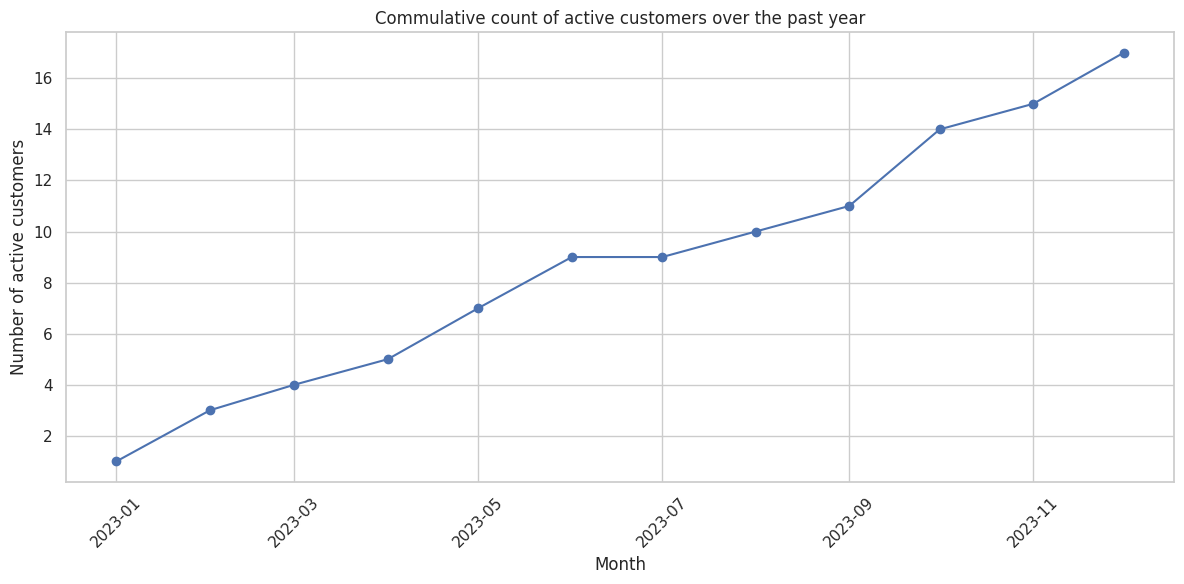

In [ ]:
months = sorted(all['Month'].unique())
active_customers = [all[(all['Start Date'] <= month) & (all['End Date'] > month)]['Customer ID'].nunique() for month in months]
plt.figure(figsize=(12, 6))
plt.plot(months, active_customers, marker='o', linestyle='-')
plt.title('Commulative count of active customers over the past year')
plt.xlabel('Month')
plt.ylabel('Number of active customers')
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
# interactive plot
fig = go.Figure()

fig.add_trace(go.Scatter(
    x=months,
    y=active_customers,
    mode='lines+markers',
    line=dict(color='royalblue', width=2),
    marker=dict(size=8),
    name='Active Customers'
))

fig.update_layout(
    title='Commulative count of active customers over the past year',
    xaxis_title='Month',
    yaxis_title='Number of active customers',
    xaxis_tickangle=-45,
    template='plotly_white',
    width=900,
    height=500
)
fig.show()


### **Task 5**
If those tables were in an SQL DB, Write a code to retrieve sum of minutes used on our service per customer.

In [ ]:
# SELECT "Customer ID", SUM("Minutes Used") FROM usage GROUP BY "Customer ID"

### **Task 6**
Sketch a very simple ERD for the files

In [ ]:
# i sketched 2 diagrams
# i used this artical from meduim as my referance https://medium.com/@ayodhya.dayananda/generating-er-diagrams-from-mysql-databases-using-python-and-graphviz-c9c33e07e65a

In [ ]:
!pip install graphviz --quiet

In [ ]:
from IPython.display import Image, display
from graphviz import Digraph

In [ ]:
def write_label(df, df_name):
  label = f"""<<TABLE><TR><TD BGCOLOR='lightblue'><B>{df_name}</B></TD></TR>"""
  for col in df.columns:
    label += f"<TR><TD ALIGN='LEFT' PORT='{col}'>{col} ({str(df[col].dtype)})</TD></TR>"
  label += "</TABLE>>"
  return label

In [ ]:
# write_label(customer, "Customer")

In [ ]:
# here i specify PK, FK, note that usage has a composite key
customer_label = """<<TABLE><TR><TD BGCOLOR='lightblue'><B>Customer</B></TD></TR>
<TR><TD ALIGN='LEFT' PORT='Customer ID'>Customer ID (int64) [PK]</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Name'>Name (object)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Email'>Email (object)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Status'>Status (object)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Active Date'>Active Date (object)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Churned Date'>Churned Date (object)</TD></TR>
</TABLE>>
"""

subscription_label = """<<TABLE><TR><TD BGCOLOR='lightblue'><B>Subscription</B></TD></TR>
<TR><TD ALIGN='LEFT' PORT='Subscription ID'>Subscription ID (float64) [PK]</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Customer ID'>Customer ID (float64) [FK]</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Plan Name'>Plan Name (object)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Start Date'>Start Date (object)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='End Date'>End Date (object)</TD></TR>
</TABLE>>
"""

usage_label = """<<TABLE><TR><TD BGCOLOR='lightblue'><B>Usage</B></TD></TR>
<TR><TD ALIGN='LEFT' PORT='Customer ID'>Customer ID (int64) [PK][FK]</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Month'>Month (object) [PK]</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Data Usage GB'>Data Usage GB (float64)</TD></TR>
<TR><TD ALIGN='LEFT' PORT='Minutes Used'>Minutes Used (int64)</TD></TR>
</TABLE>>
"""

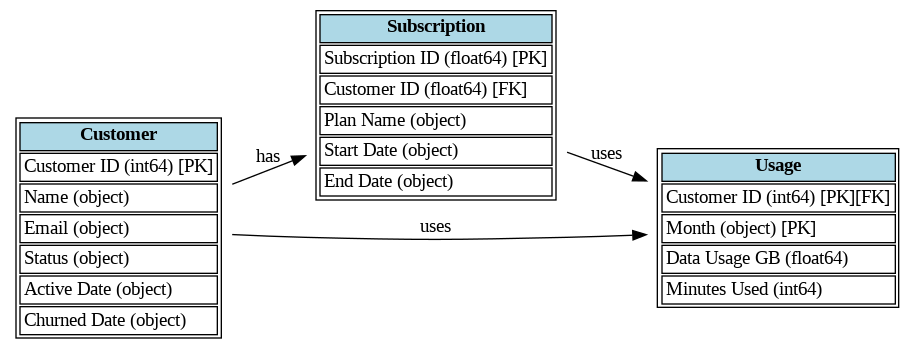

In [ ]:
dot = Digraph('ERD', filename='erd_subgraphs.gv')
dot.attr(rankdir='LR')
dot.attr('node', shape='record', height='.1')

dot.node('Customer', customer_label, shape="plaintext")
dot.node('Subscription', subscription_label, shape="plaintext")
dot.node('Usage', usage_label, shape="plaintext")

dot.edge('Customer', 'Subscription', label='has')
dot.edge('Customer', 'Usage', label='uses')
dot.edge('Subscription', 'Usage', label='uses')

display(Image(dot.pipe(format='png')))


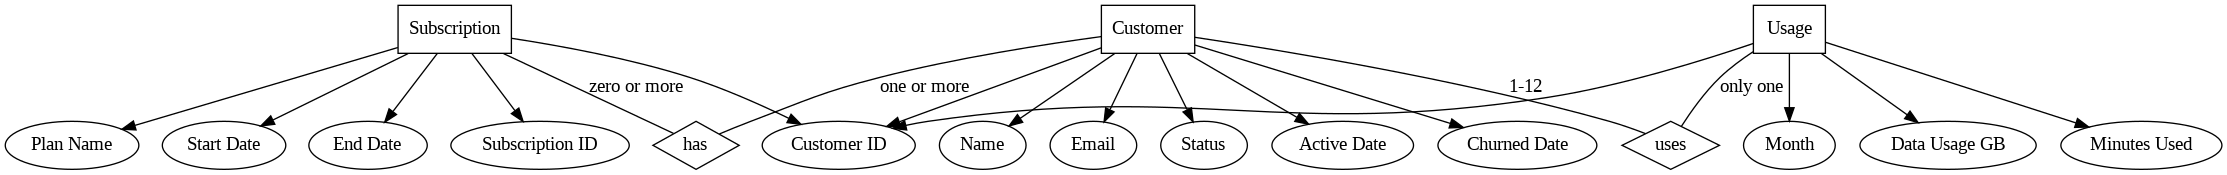

In [ ]:
dot = Digraph('ER_Diagram', format='png')

dot.node('Subscription', 'Subscription', shape='box')
for col in subscription.columns:
  dot.node(col, col, shape='ellipse')
  dot.edge('Subscription', col)


dot.node('Customer', 'Customer', shape='box')
for col in customer.columns:
  dot.node(col, col, shape='ellipse')
  dot.edge('Customer', col)

dot.node('Usage', 'Usage', shape='box')
for col in usage.columns:
  dot.node(col, col, shape='ellipse')
  dot.edge('Usage', col)

dot.node('has', "has", shape='diamond')
dot.node('uses', "uses", shape='diamond')

dot.edge('Customer', 'has', arrowhead='none', label='one or more')
dot.edge('Subscription', 'has', arrowhead='none', label='zero or more')

dot.edge('Customer', 'uses', arrowhead='none', label='1-12')
dot.edge('Usage', 'uses', arrowhead='none', label='only one')


display(Image(dot.pipe(format='png')))
